# Agrupamento de Municípios por Perfil Epidemiológico — K-Means

Agrupamento dos 1.590 municípios de SP, RJ e MG com base em **4 features de mortalidade** do ano de
referência 2022:

| Feature | Descrição |
|---|---|
| `taxa_mortalidade` | Óbitos por 100 mil habitantes (SIM 2022) |
| `prop_cid_IX` | Proporção de óbitos por doenças do aparelho circulatório (CAUSABAS iniciando com 'I') |
| `prop_cid_X` | Proporção de óbitos por doenças do aparelho respiratório (CAUSABAS iniciando com 'J') |
| `prop_cid_I` | Proporção de óbitos por doenças infecciosas/parasitárias (CAUSABAS iniciando com 'A' ou 'B') |

O runner de produção usa também a taxa de internações do SIH como quinta feature; este recorte
contém apenas o SIM.

> **Fonte dos dados:** recorte real do SIM/DataSUS (óbitos por município de residência) para
> SP, RJ e MG, agregado por município × ano × grupo CID-10 × sexo × faixa etária em
> `data/notebooks/sim_agregado.parquet`. O arquivo é gerado por
> `scripts/build_notebook_extract.py` a partir dos arquivos brutos do DataSUS, e as contagens
> batem com os microdados. População: estimativas IBGE/TCU
> (`backend/seeds/data/tcu_populacao.csv`). Todas as taxas são brutas, sem padronização por idade.
>
> O clustering de produção roda sobre os 5.570 municípios do país com 5 features, então os
> grupos daqui não são os mesmos. Os rótulos dos clusters no dashboard (`CLUSTER_NOME_MAP` em
> `backend/ml/run_clustering.py`) refletem o dado de produção e não são alterados por este notebook.

In [1]:
import logging, os
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("cmdstanpy").addHandler(logging.NullHandler())  # impede o handler INFO padrão
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")

import warnings
warnings.filterwarnings('ignore')

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Carregar população via pandas — DuckDB sniffer falha no em-dash UTF-8 do arquivo TCU
pop_df = pd.read_csv(
    '../backend/seeds/data/tcu_populacao.csv',
    skiprows=1,
    dtype={'codigo_ibge_6': str, 'ano': int, 'populacao_total': int}
)

con = duckdb.connect()  # in-memory — sem dependência de PostgreSQL
con.register('dim_populacao_csv', pop_df)

# Extrato real do SIM (SP, RJ e MG, 2015-2022), gerado por scripts/build_notebook_extract.py
OBITOS_PARQUET = '../data/notebooks/sim_agregado.parquet'
con.execute(f"CREATE VIEW obitos AS SELECT * RENAME (municipio_codigo AS codigo_ibge_6) FROM read_parquet('{OBITOS_PARQUET}')")

# Ano de referência para o clustering (features epidemiológicas)
ANO_REF = 2022
FEATURE_NAMES = ['taxa_mortalidade', 'prop_cid_IX', 'prop_cid_X', 'prop_cid_I']

print(f"Ano de referência: {ANO_REF}")
print(f"Features epidemiológicas: {FEATURE_NAMES}")

Ano de referência: 2022
Features epidemiológicas: ['taxa_mortalidade', 'prop_cid_IX', 'prop_cid_X', 'prop_cid_I']


In [2]:
# Matriz de features por município para o ano de referência
features_df = con.execute("""
    WITH obitos_ref AS (
        SELECT
            codigo_ibge_6,
            SUM(obitos) AS total_obitos,
            SUM(CASE WHEN capitulo_cid = 'I' THEN obitos ELSE 0 END)        AS obitos_circ,
            SUM(CASE WHEN capitulo_cid = 'J' THEN obitos ELSE 0 END)        AS obitos_resp,
            SUM(CASE WHEN capitulo_cid IN ('A', 'B') THEN obitos ELSE 0 END) AS obitos_infec
        FROM obitos
        WHERE ano = ?
        GROUP BY codigo_ibge_6
    )
    SELECT
        o.codigo_ibge_6,
        p.populacao_total,
        o.total_obitos,
        o.total_obitos * 100000.0 / p.populacao_total AS taxa_mortalidade,
        o.obitos_circ  * 1.0 / o.total_obitos         AS prop_cid_IX,
        o.obitos_resp  * 1.0 / o.total_obitos         AS prop_cid_X,
        o.obitos_infec * 1.0 / o.total_obitos         AS prop_cid_I
    FROM obitos_ref o
    JOIN dim_populacao_csv p
        ON o.codigo_ibge_6 = p.codigo_ibge_6 AND p.ano = ?
    WHERE p.populacao_total > 0
    ORDER BY o.codigo_ibge_6
""", [ANO_REF, ANO_REF]).df()

print(f"Municípios com óbitos e população em {ANO_REF}: {len(features_df)}")
print(features_df[FEATURE_NAMES].describe().round(3))

Municípios com óbitos e população em 2022: 1590
       taxa_mortalidade  prop_cid_IX  prop_cid_X  prop_cid_I
count          1590.000     1590.000    1590.000    1590.000
mean            873.113        0.254       0.130       0.089
std             201.317        0.065       0.051       0.042
min             375.940        0.000       0.000       0.000
25%             730.394        0.213       0.099       0.064
50%             858.762        0.250       0.125       0.085
75%             989.508        0.291       0.157       0.109
max            2008.734        0.667       0.368       0.400


In [3]:
# Normalização com StandardScaler
# StandardScaler é preferido ao MinMaxScaler para K-Means com dados epidemiológicos,
# pois lida melhor com municípios outliers sem comprimir toda a distribuição.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_df[FEATURE_NAMES].values)

print(f"Matriz normalizada: {X_scaled.shape}")
print(f"Média pós-normalização (deve ser ~0): {X_scaled.mean(axis=0).round(4)}")
print(f"Std pós-normalização (deve ser ~1):   {X_scaled.std(axis=0).round(4)}")

Matriz normalizada: (1590, 4)
Média pós-normalização (deve ser ~0): [ 0.  0. -0.  0.]
Std pós-normalização (deve ser ~1):   [1. 1. 1. 1.]


## Método Elbow para Seleção de k

O método elbow plota a **inércia** (soma das distâncias quadráticas ao centroide) para diferentes
valores de k. O ponto de inflexão da curva — onde a redução de inércia começa a diminuir
significativamente — indica o k ótimo.

Para dados epidemiológicos municipais, geralmente k=5–8 é o intervalo mais interpretável. Com as
quatro features deste modelo, os perfis esperados são combinações como: mortalidade geral baixa
ou alta (`taxa_mortalidade`), peso maior das doenças circulatórias (`prop_cid_IX`), das
respiratórias (`prop_cid_X`) ou das infecciosas (`prop_cid_I`).

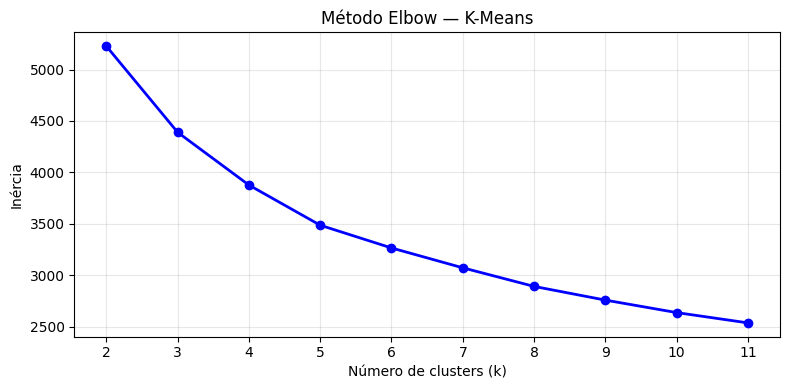

Inércias por k:
  k= 2: 5226.87
  k= 3: 4389.87
  k= 4: 3877.05
  k= 5: 3486.78
  k= 6: 3265.85
  k= 7: 3072.94
  k= 8: 2892.26
  k= 9: 2759.09
  k=10: 2637.84
  k=11: 2537.70


In [4]:
# Método Elbow — inércia para k em range(2, 12)
inertias = []
k_range = range(2, 12)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertias, 'bo-', linewidth=2, markersize=6)
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia')
plt.title('Método Elbow — K-Means')
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Inércias por k:")
for k, inertia in zip(k_range, inertias):
    print(f"  k={k:2d}: {inertia:.2f}")

In [5]:
# k=6, o mesmo usado pelo runner de produção; o elbow acima não mostra cotovelo nítido
# Sempre usar n_init=10 explícito para reproducibilidade
K_SELECTED = 6

km = KMeans(n_clusters=K_SELECTED, random_state=42, n_init=10)
km.fit(X_scaled)
labels = km.labels_

sil = silhouette_score(X_scaled, labels)
print(f"k={K_SELECTED}, silhouette_score={sil:.4f}")
print(f"\nInterpretação: silhouette > 0.5 = clusters bem definidos; 0.25-0.5 = moderado")

k=6, silhouette_score=0.1522

Interpretação: silhouette > 0.5 = clusters bem definidos; 0.25-0.5 = moderado


In [6]:
# Projeção PCA para visualização 2D dos clusters
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    'pca_x': X_pca[:, 0],
    'pca_y': X_pca[:, 1],
    'cluster': labels
})

explained_var = pca.explained_variance_ratio_
print(f"PCA variância explicada:")
print(f"  PC1: {explained_var[0]:.2%}")
print(f"  PC2: {explained_var[1]:.2%}")
print(f"  Total (PC1+PC2): {sum(explained_var):.2%}")

PCA variância explicada:
  PC1: 30.85%
  PC2: 29.22%
  Total (PC1+PC2): 60.06%


## Projeção PCA dos Clusters

Dispersão dos municípios no espaço PCA (primeiras 2 componentes principais).
Cada cor representa um cluster K-Means.

A variância explicada pelas 2 primeiras componentes indica o quanto da variabilidade original
é capturada pelo gráfico 2D. Valores < 60% indicam que a projeção 2D perde informação relevante
— os clusters fazem mais sentido no espaço original de 4 dimensões.

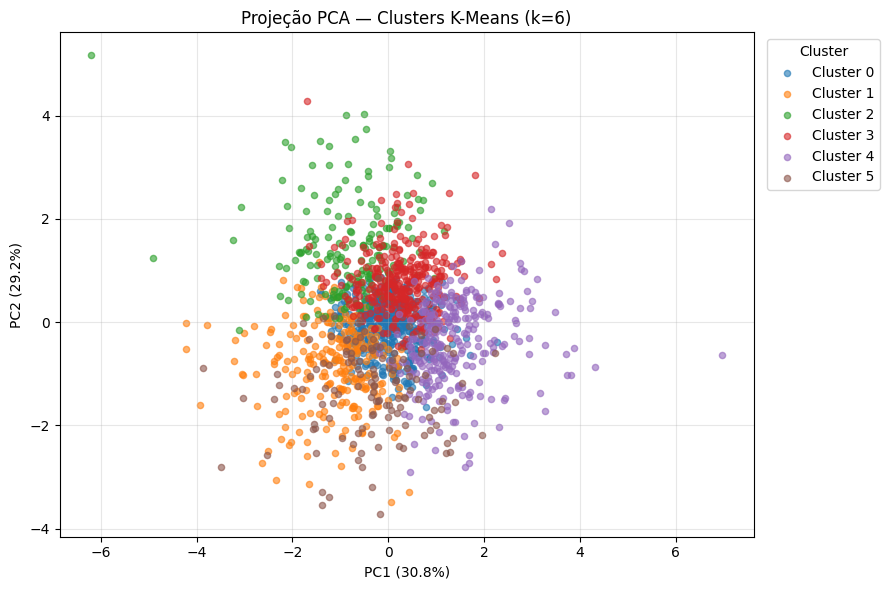

In [7]:
# Scatter plot PCA colorido por cluster
colors = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(9, 6))
for c in range(K_SELECTED):
    mask = pca_df['cluster'] == c
    ax.scatter(
        pca_df.loc[mask, 'pca_x'],
        pca_df.loc[mask, 'pca_y'],
        label=f'Cluster {c}',
        alpha=0.6,
        s=20,
        color=colors[c % len(colors)]
    )

ax.set_xlabel(f'PC1 ({explained_var[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained_var[1]:.1%})')
ax.set_title(f'Projeção PCA — Clusters K-Means (k={K_SELECTED})')
ax.legend(title='Cluster', bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Perfil de centroide — inverter a normalização para escala original das features
# Isso permite interpretar os clusters em termos das features originais
centroids_scaled = km.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=FEATURE_NAMES
)
centroid_df.index.name = 'cluster_id'

print("Perfil de centroide (escala original):")
print(centroid_df.round(4).to_string())

Perfil de centroide (escala original):
            taxa_mortalidade  prop_cid_IX  prop_cid_X  prop_cid_I
cluster_id                                                       
0                   946.9001       0.2441      0.1183      0.0853
1                   852.6922       0.2082      0.2054      0.0737
2                   835.8895       0.2217      0.1127      0.1650
3                   687.2636       0.2364      0.1014      0.0831
4                   847.3280       0.3465      0.1187      0.0664
5                  1287.8245       0.2599      0.1487      0.0882


## Atribuição de Nomes aos Clusters (cluster_nome_map)

Os rótulos abaixo resumem os **perfis de centroide** da célula anterior, comparados à mediana dos
municípios (859 óbitos por 100 mil; 25,0% circulatório; 12,5% respiratório; 8,5% infeccioso).
Eles não são os rótulos de `CLUSTER_NOME_MAP` usados pelo dashboard (ver nota no início).

**Como interpretar:**
- `taxa_mortalidade` alta → mortalidade geral elevada (verificar porte e idade da população)
- `prop_cid_IX` alta → peso das doenças circulatórias
- `prop_cid_X` alta → peso das doenças respiratórias
- `prop_cid_I` alta → peso das doenças infecciosas, que em 2022 ainda inclui COVID-19 (B34.2)

In [9]:
# Rótulos descritivos dos centroides (célula anterior)
cluster_nome_map = {
    0: "Mortalidade Acima da Média",
    1: "Peso Respiratório Elevado (Pequeno Porte)",
    2: "Peso Infeccioso Elevado (Pequeno Porte)",
    3: "Baixa Mortalidade",
    4: "Predominância Circulatória",
    5: "Alta Mortalidade Geral (Pequeno Porte)",
}
print("cluster_nome_map definido com", len(cluster_nome_map), "clusters.")
print()
for k, v in cluster_nome_map.items():
    print(f"  {k}: {v}")

cluster_nome_map definido com 6 clusters.

  0: Mortalidade Acima da Média
  1: Peso Respiratório Elevado (Pequeno Porte)
  2: Peso Infeccioso Elevado (Pequeno Porte)
  3: Baixa Mortalidade
  4: Predominância Circulatória
  5: Alta Mortalidade Geral (Pequeno Porte)


### Nota: estrutura fraca e efeito de denominador pequeno

O **silhouette de 0,15** indica grupos pouco separados, e o gráfico elbow não tem cotovelo
nítido. Faz sentido: em 2022, os municípios de SP, RJ e MG têm perfis de causa parecidos
(desvio-padrão de 6,5 pontos percentuais na proporção circulatória), e os grupos se formam mais
por gradação do que por perfis distintos. O runner de produção agrupa os 5.570 municípios do
país com a taxa de internações do SIH como quinta feature, então seus grupos e rótulos são
diferentes dos deste notebook.

Os clusters definidos por uma única dimensão extrema são os de municípios menores. O
**Cluster 5** (128 municípios, população mediana de 4,7 mil, 1.288 óbitos por 100 mil) e os
**Clusters 1 e 2** (respiratório e infeccioso, ambos com mediana de 7,3 mil habitantes) têm
mediana de 56 a 63 óbitos no ano, então poucos óbitos a mais bastam para deslocar o município de
grupo. Esses rótulos descrevem o ano de 2022 e devem ser lidos com cautela. Os clusters 0, 3 e 4
reúnem municípios maiores e mais estáveis, e é neles que ficam as capitais: Rio de Janeiro no
0, Belo Horizonte no 3 e São Paulo no 4.

Tamanho dos clusters:
0    407
1    251
2    178
3    345
4    281
5    128

Total de municípios: 1590
Cluster maior: 407 municípios (Cluster 0)
Cluster menor: 128 municípios (Cluster 5)


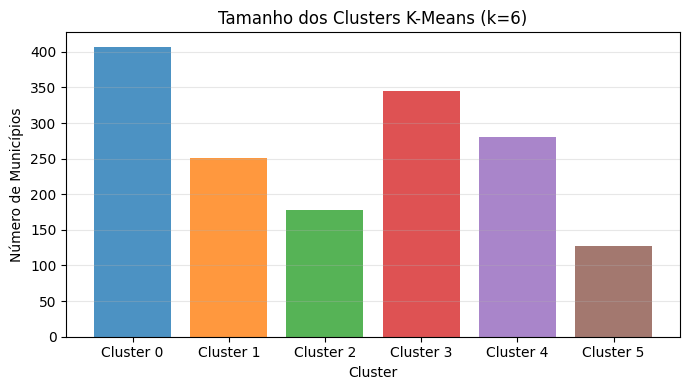

In [10]:
# Distribuição de tamanho dos clusters
cluster_sizes = pd.Series(labels).value_counts().sort_index()
print("Tamanho dos clusters:")
print(cluster_sizes.to_string())
print(f"\nTotal de municípios: {len(labels)}")
print(f"Cluster maior: {cluster_sizes.max()} municípios (Cluster {cluster_sizes.idxmax()})")
print(f"Cluster menor: {cluster_sizes.min()} municípios (Cluster {cluster_sizes.idxmin()})")

# Barplot dos tamanhos
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    [f'Cluster {i}' for i in cluster_sizes.index],
    cluster_sizes.values,
    color=[colors[i % len(colors)] for i in cluster_sizes.index],
    alpha=0.8
)
ax.set_xlabel('Cluster')
ax.set_ylabel('Número de Municípios')
ax.set_title(f'Tamanho dos Clusters K-Means (k={K_SELECTED})')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()